# Minimum Wages and County Teen Employment

This notebook studies the relationship between state minimum-wage increases and county-level teen employment using the `mpdta` panel. The goal is to learn fixed effects and difference-in-differences methods, not to claim a definitive policy effect.

The data are distributed with Callaway and Sant'Anna's R `did` package: [dataset documentation](https://bcallaway11.github.io/did/reference/mpdta.html), [official data file](https://raw.githubusercontent.com/bcallaway11/did/master/data/mpdta.rda). The checked-in CSV is an export of that file.

## Analysis map

- Unit: county (`countyreal`); time: year (`year`).
- Outcome: log teen employment (`lemp`).
- Treatment cohort: `first.treat`; zero denotes never treated.
- The year-specific treatment indicator is one from the cohort's adoption year onward.

The core estimates are a county- and year-fixed-effects TWFE DiD and a TWFE event study. Staggered-treatment-robust group-time ATT is an optional extension after the core analysis works.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

## 1. Inspect the panel and treatment timing

In [8]:
candidate_paths = [Path("../data/mpdta.csv"), Path("data/mpdta.csv")]
data_path = next(path for path in candidate_paths if path.exists())
df = pd.read_csv(data_path)

print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing"))
print("Duplicate county-year rows:", df.duplicated(["countyreal", "year"]).sum())
print("Years per county:")
display(df.groupby("countyreal")["year"].nunique().value_counts().sort_index())
print("Treatment cohorts (county counts):")
display(df[["countyreal", "first.treat"]].drop_duplicates()["first.treat"].value_counts().sort_index())

Shape: (2500, 6)


,year,countyreal,lpop,lemp,first.treat,treat
0,2003,8001,5.896761,8.461469,2007,1
1,2004,8001,5.896761,8.336870,2007,1
2,2005,8001,5.896761,8.340217,2007,1
3,2006,8001,5.896761,8.378161,2007,1
4,2007,8001,5.896761,8.487352,2007,1


year           0
countyreal     0
lpop           0
lemp           0
first.treat    0
treat          0
Name: missing, dtype: int64

Duplicate county-year rows: 0
Years per county:


year
5    500
Name: count, dtype: int64

Treatment cohorts (county counts):


first.treat
0       309
2004     20
2006     40
2007    131
Name: count, dtype: int64

In [9]:
df["ever_treated"] = (df["first.treat"] > 0).astype(int)
df["treated"] = (
    (df["first.treat"] > 0) & (df["year"] >= df["first.treat"])
).astype(int)
df["event_time"] = (
    (df["year"] - df["first.treat"])
    .where(df["first.treat"] > 0)
    .astype("Int64")
)

# countyreal is a county FIPS code in this dataset; its leading zero, if any, is omitted.
df["state_fips"] = df["countyreal"].astype(int) // 1000
display(pd.crosstab(df["year"], df["treated"], margins=True))

treated,0,1,All
year,,,
2003,500,0,500
2004,480,20,500
2005,480,20,500
2006,440,60,500
2007,309,191,500
All,2209,291,2500


## 2. County and year fixed effects: baseline TWFE DiD

The regression absorbs stable county differences and shocks common to each year. The `treated` coefficient is the conventional pooled TWFE estimate. Standard errors below are clustered by state, the policy-assignment level; `state_fips` is derived from the county FIPS identifier.

In [10]:
twfe = smf.ols(
    "lemp ~ treated + C(countyreal) + C(year)", data=df
).fit(cov_type="cluster", cov_kwds={"groups": df["state_fips"]})

beta = twfe.params["treated"]
se = twfe.bse["treated"]
ci_low, ci_high = twfe.conf_int().loc["treated"]
p_value = twfe.pvalues["treated"]
print(f"Treatment coefficient: {beta:.4f}")
print(f"State-clustered standard error: {se:.4f}")
print(f"95% confidence interval: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"p-value: {p_value:.4f}")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Treatment coefficient: -0.0365
State-clustered standard error: 0.0253
95% confidence interval: [-0.0862, 0.0131]
p-value: 0.1492


## 3. Interpret the treatment coefficient

Because the outcome is in logs, `100 * (exp(beta) - 1)` converts the coefficient to an approximate percentage change in teen employment. A causal interpretation requires assumptions such as parallel trends and no anticipation. Do not interpret statistical significance alone as evidence that these assumptions hold.

In [11]:
estimate_pct = 100 * np.expm1(beta)
ci_pct = 100 * np.expm1([ci_low, ci_high])
print(f"Approximate percentage effect: {estimate_pct:.2f}%")
print(f"Transformed 95% CI: [{ci_pct[0]:.2f}%, {ci_pct[1]:.2f}%]")

Approximate percentage effect: -3.59%
Transformed 95% CI: [-8.26%, 1.32%]


## 4. TWFE event study

Event time is calendar year minus the county's first treatment year. The year immediately before treatment (`-1`) is the omitted reference. Never-treated counties have zero for every event-time indicator and contribute to the comparison group.

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


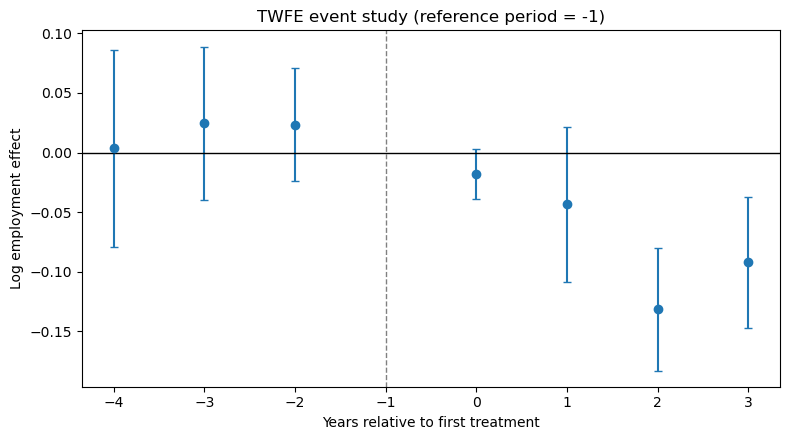

,event_time,estimate,ci_low,ci_high
0,-4,0.0035,-0.0791,0.0862
1,-3,0.0246,-0.0398,0.0890
2,-2,0.0234,-0.0243,0.0710
3,0,-0.0181,-0.0392,0.0029
4,1,-0.0435,-0.1087,0.0218
5,2,-0.1318,-0.1831,-0.0805
6,3,-0.0922,-0.1471,-0.0374


In [12]:
event_window = range(-4, 4)
reference_period = -1
event_terms = []
term_to_event_time = {}

for event_time in event_window:
    if event_time == reference_period:
        continue
    term = f"event_m{abs(event_time)}" if event_time < 0 else f"event_p{event_time}"
    df[term] = (
        (df["first.treat"] > 0)
        & ((df["year"] - df["first.treat"]) == event_time)
    ).astype(int)
    event_terms.append(term)
    term_to_event_time[term] = event_time

event_formula = "lemp ~ " + " + ".join(
    event_terms + ["C(countyreal)", "C(year)"]
)
event_fit = smf.ols(event_formula, data=df).fit(
    cov_type="cluster", cov_kwds={"groups": df["state_fips"]}
)

event_results = pd.DataFrame(
    [
        {
            "event_time": term_to_event_time[term],
            "estimate": event_fit.params[term],
            "ci_low": event_fit.conf_int().loc[term, 0],
            "ci_high": event_fit.conf_int().loc[term, 1],
        }
        for term in event_terms
    ]
).sort_values("event_time")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(
    event_results["event_time"],
    event_results["estimate"],
    yerr=[
        event_results["estimate"] - event_results["ci_low"],
        event_results["ci_high"] - event_results["estimate"],
    ],
    fmt="o",
    capsize=3,
)
ax.axhline(0, color="black", linewidth=1)
ax.axvline(reference_period, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Years relative to first treatment", ylabel="Log employment effect")
ax.set_title("TWFE event study (reference period = -1)")
fig.tight_layout()
plt.show()
display(event_results.round(4))

## 5. Parallel trends and limitations

- Parallel trends is an identifying assumption, not a result of the regression. Pre-treatment coefficients can reveal some deviations, but a short pre-period gives limited power and cannot prove the assumption.
- With staggered adoption and heterogeneous effects, conventional TWFE event-study coefficients can mix effects from different cohorts and periods. Treat these estimates as a learning baseline, not the final robust estimate.
- Minimum-wage policy changes occur at the state level, while outcomes are county-level. The standard errors above cluster by state using the FIPS encoding; verify that mapping if the data source changes.
- The panel covers only 2003-2007, and `lemp` is log employment rather than an employment rate. Population and other confounding changes may matter.
- The dataset is an illustrative subset; results should not be presented as a definitive evaluation of minimum-wage policy.

## Optional extension: staggered-treatment-robust DiD

After the core notebook runs and its assumptions are understood, estimate group-time ATT(g,t) and aggregate dynamic effects with a Callaway-Sant'Anna implementation. Compare its event-time estimates and uncertainty with the TWFE event study. Keep that estimator out of the core dependency list for now.